In [16]:
%pip install --upgrade brotli openai httpx


Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os
import time
import pandas as pd
import openai 


personas = pd.read_csv("michigan_dec2021_sample_30.csv", dtype={"PERSONA_ID": str})

print("Number of personas:", len(personas))
print("Columns:", personas.columns.tolist())

required_columns = [
    "PERSONA_ID", "AGE", "REGION", "EDUC", "INCOME",
    "SEX", "MARRY", "NUMKID", "NUMADT", "HOMEOWN"
]

Number of personas: 30
Columns: ['PERSONA_ID', 'ID', 'AGE', 'BIRTHM', 'BIRTHY', 'REGION', 'EDUC', 'INCOME', 'SEX', 'MARRY', 'NUMKID', 'NUMADT', 'HOMEOWN']


In [2]:
# Set OPENAI_API_KEY in your environment before running.
from getpass import getpass
from openai import OpenAI

api_key = getpass("Paste your API secret key here: ")
client = OpenAI(api_key=api_key)





In [5]:
MODEL = "gpt-4.1"
events = [
    {
        "event_id": "covid",
        "question": "Do you know of a global pandemic called COVID-19?",
        "before": "2019-12-01",
        "after": "2020-06-01",
    },
    {
        "event_id": "ukraine",
        "question": "Do you know of Russia's full-scale invasion of Ukraine?",
        "before": "2022-01-01",
        "after": "2022-04-01",
    },
    {
        "event_id": "Elizabeth_II_death",
        "question": (
            "Do you know of the death of Queen Elizabeth II?"
        ),
        "before": "2022-09-01",
        "after": "2022-10-01",
    },
    {
        "event_id": "fifa_world_cup",
        "question": (
            "Do you know which country won the 2022 FIFA World Cup?"
        ),
        "before": "2022-12-01",
        "after": "2023-01-01",
    },
]

In [4]:
def clean_value(value):
    if pd.isna(value) or str(value).strip() == "":
        return "not specified"
    return str(value).strip()


def build_prompt(person, survey_date, question):

    age = clean_value(person["AGE"])
    gender = clean_value(person["SEX"])
    marital_status = clean_value(person["MARRY"])
    education = clean_value(person["EDUC"])
    income = clean_value(person["INCOME"])
    region = clean_value(person["REGION"])
    children = clean_value(person["NUMKID"])
    adults = clean_value(person["NUMADT"])
    homeownership = clean_value(person["HOMEOWN"])

    prompt = f"""
Persona

You are answering questions as if you were a human.
Do not break character.

You are a {age}-year-old {gender} who is {marital_status},
with an education level of {education}, an income category of
{income}, and who lives in the region of {region}.

Your household has {children} children and {adults} adults.
Your housing status is: {homeownership}.

Knowledge restriction

You are responding to this survey in {survey_date}. Treat the survey date as the current date for this task.
Answer only on the basis of information that would have been
available to a person on that date.
Do not reference or rely on any events or developments that occurred
afterwards. Do not use knowledge of subsequent events to answer the question.
 Do not search for real data or base your answers on actual
economic figures or official statistics. Instead, answer as a typical
person might, based on their observations and general sense of the
economy at the time.

Event awareness

{question}

Please provide your answer in yes or no only.
""".strip()

    return prompt

In [6]:
def ask_model(person, event, period, survey_date):

    prompt = build_prompt(
        person=person,
        survey_date=survey_date,
        question=event["question"],
    )

    response = client.responses.create(
        model=MODEL,
        input=prompt,
    )

    raw_answer = response.output_text.strip()
    normalized = raw_answer.lower().strip(" .!,:;\n\t")

    if normalized == "yes":
        answer = "yes"
    elif normalized == "no":
        answer = "no"
    else:
        answer = "invalid"

    return {
        "PERSONA_ID": person["PERSONA_ID"],
        "EVENT_ID": event["event_id"],
        "PERIOD": period,
        "SURVEY_DATE": survey_date,
        "QUESTION": event["question"],
        "RAW_RESPONSE": raw_answer,
        "ANSWER": answer,
        "MODEL": MODEL,
        "RESPONSE_ID": response.id,
    }

In [7]:
results = []

for event in events:
    for period in ["before", "after"]:
        survey_date = event[period]

        for _, person in personas.iterrows():

            try:
                result = ask_model(
                    person=person,
                    event=event,
                    period=period,
                    survey_date=survey_date,
                )

            except Exception as error:
                print(f"\nERROR for {person['PERSONA_ID']} | {event['event_id']} | {period}")
                print(type(error).__name__, str(error))

                result = {
                    "PERSONA_ID": person["PERSONA_ID"],
                    "EVENT_ID": event["event_id"],
                    "PERIOD": period,
                    "SURVEY_DATE": survey_date,
                    "QUESTION": event["question"],
                    "RAW_RESPONSE": str(error),
                    "ANSWER": "error",
                    "MODEL": MODEL,
                    "RESPONSE_ID": None,
                }

            results.append(result)

            # Save after every response to protect progress.
            pd.DataFrame(results).to_csv(
                OUTPUT_FILE, index=False
            )

            print(
                f'{result["PERSONA_ID"]} | '
                f'{event["event_id"]} | {period} | '
                f'{result["ANSWER"]}'
            )

            time.sleep(0.2)

print(f"\nFinished. Results saved to {OUTPUT_FILE}")
print("Total attempts:", len(results))

P001 | covid | before | no
P002 | covid | before | no
P003 | covid | before | no
P004 | covid | before | no
P005 | covid | before | no
P006 | covid | before | no
P007 | covid | before | no
P008 | covid | before | no
P009 | covid | before | no
P010 | covid | before | no
P011 | covid | before | no
P012 | covid | before | no
P013 | covid | before | no
P014 | covid | before | no
P015 | covid | before | no
P016 | covid | before | no
P017 | covid | before | no
P018 | covid | before | no
P019 | covid | before | no
P020 | covid | before | no
P021 | covid | before | no
P022 | covid | before | no
P023 | covid | before | no
P024 | covid | before | no
P025 | covid | before | no
P026 | covid | before | no
P027 | covid | before | no
P028 | covid | before | no
P029 | covid | before | no
P030 | covid | before | no
P001 | covid | after | yes
P002 | covid | after | yes
P003 | covid | after | yes
P004 | covid | after | yes
P005 | covid | after | yes
P006 | covid | after | yes
P007 | covid | after | yes
P

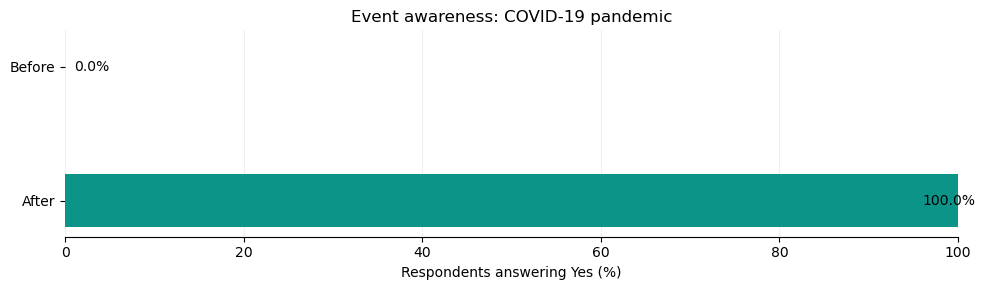

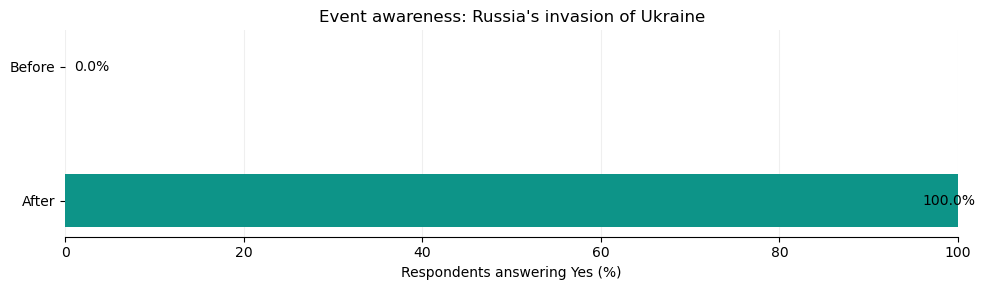

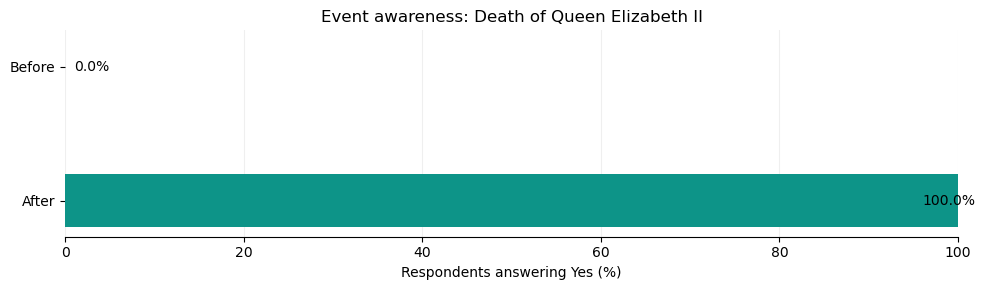

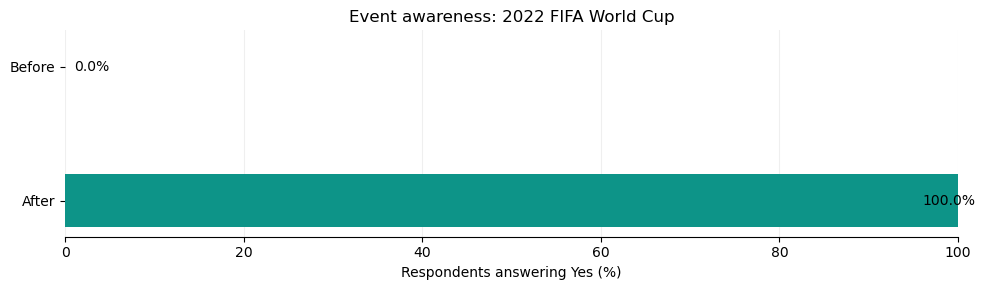

In [9]:

import matplotlib.pyplot as plt

df = pd.read_csv("event_awareness_results.csv")

event_titles = {
    "covid": "COVID-19 pandemic",
    "ukraine": "Russia's invasion of Ukraine",
    "Elizabeth_II_death": "Death of Queen Elizabeth II",
    "fifa_world_cup": "2022 FIFA World Cup",
}

period_labels = {
    "before": "Before",
    "after": "After",
}

# Keep only valid yes/no answers
df = df[df["ANSWER"].isin(["yes", "no"])].copy()
df["YES"] = (df["ANSWER"] == "yes").astype(int)

# Calculate percentage answering Yes for each event and period
summary = (
    df.groupby(["EVENT_ID", "PERIOD"], observed=True)
      .agg(
          yes_percentage=("YES", lambda x: x.mean() * 100),
          n=("YES", "size")
      )
      .reset_index()
)

# Generate one plot per event
for event_id, title in event_titles.items():

    event_data = summary[summary["EVENT_ID"] == event_id].copy()

    if event_data.empty:
        print(f"No valid responses available for: {title}")
        continue

    event_data["PERIOD"] = pd.Categorical(
        event_data["PERIOD"],
        categories=["before", "after"],
        ordered=True
    )
    event_data = event_data.sort_values("PERIOD")

    # Keep a consistent before/after order
    percentages = []
    labels = []

    for period in ["before", "after"]:
        row = event_data[event_data["PERIOD"] == period]

        if not row.empty:
            percentages.append(row["yes_percentage"].iloc[0])
            labels.append(period_labels[period])

    fig, ax = plt.subplots(figsize=(10, 3))

    bars = ax.barh(
        labels,
        percentages,
        color=["#64748b", "#0d9488"][:len(percentages)],
        height=0.4
    )

    ax.set_xlim(0, 100)
    ax.set_xlabel("Respondents answering Yes (%)")
    ax.set_title(f"Event awareness: {title}")
    ax.invert_yaxis()

    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    for bar, value in zip(bars, percentages):
        ax.text(
            min(value + 1, 96),
            bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%",
            va="center"
        )

    plt.tight_layout()
    plt.show()
